In [381]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import phik
import warnings
warnings.simplefilter('ignore')

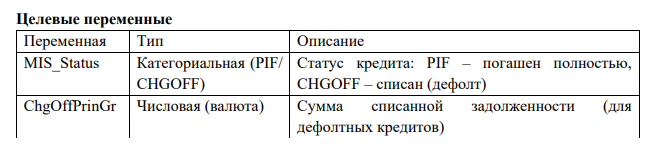
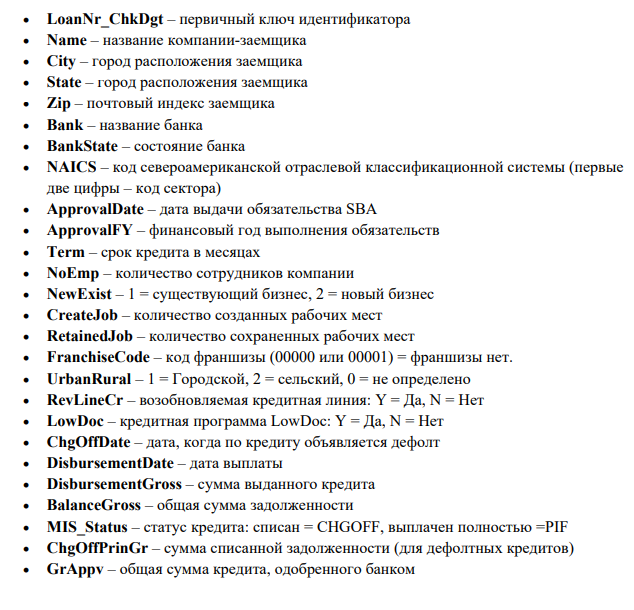
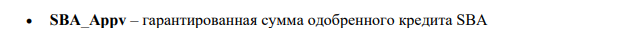

In [382]:
df = pd.read_csv('SBAnational.csv')

In [3]:
df.duplicated().sum()

np.int64(0)

In [4]:
df.isnull().sum()

LoanNr_ChkDgt             0
Name                     14
City                     30
State                    14
Zip                       0
Bank                   1559
BankState              1566
NAICS                     0
ApprovalDate              0
ApprovalFY                0
Term                      0
NoEmp                     0
NewExist                136
CreateJob                 0
RetainedJob               0
FranchiseCode             0
UrbanRural                0
RevLineCr              4528
LowDoc                 2582
ChgOffDate           736465
DisbursementDate       2368
DisbursementGross         0
BalanceGross              0
MIS_Status             1997
ChgOffPrinGr              0
GrAppv                    0
SBA_Appv                  0
dtype: int64

## 1. EDA

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 899164 entries, 0 to 899163
Data columns (total 27 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   LoanNr_ChkDgt      899164 non-null  int64  
 1   Name               899150 non-null  str    
 2   City               899134 non-null  str    
 3   State              899150 non-null  str    
 4   Zip                899164 non-null  int64  
 5   Bank               897605 non-null  str    
 6   BankState          897598 non-null  str    
 7   NAICS              899164 non-null  int64  
 8   ApprovalDate       899164 non-null  str    
 9   ApprovalFY         899164 non-null  object 
 10  Term               899164 non-null  int64  
 11  NoEmp              899164 non-null  int64  
 12  NewExist           899028 non-null  float64
 13  CreateJob          899164 non-null  int64  
 14  RetainedJob        899164 non-null  int64  
 15  FranchiseCode      899164 non-null  int64  
 16  UrbanRural   

In [6]:
df['NAICS'] = df['NAICS'].apply(lambda n: str(n)[:2])

In [7]:
def explore_by_nomin(col):
    default_rate = df.groupby(col)['MIS_Status'].apply(
    lambda x: (x == 'CHGOFF').sum() / len(x)).sort_values(ascending=False)
    
    print(f'Топ 10 долей по {col}')
    print(default_rate.head(10))
    
    plt.figure(figsize=(14,8))
    sns.barplot(
        x=default_rate.values, 
        y=default_rate.index,
        orient='h'
    )
    plt.title(f'Доля дефолтов по {col}')
    plt.xlabel('Доля дефолтов')
    plt.ylabel(f'{col}')
    plt.tight_layout()

Топ 10 долей по State
State
FL    0.273561
DC    0.239926
GA    0.239574
NV    0.232178
IL    0.226128
MI    0.224483
TN    0.212060
AZ    0.207419
SC    0.204574
NJ    0.200915
Name: MIS_Status, dtype: float64


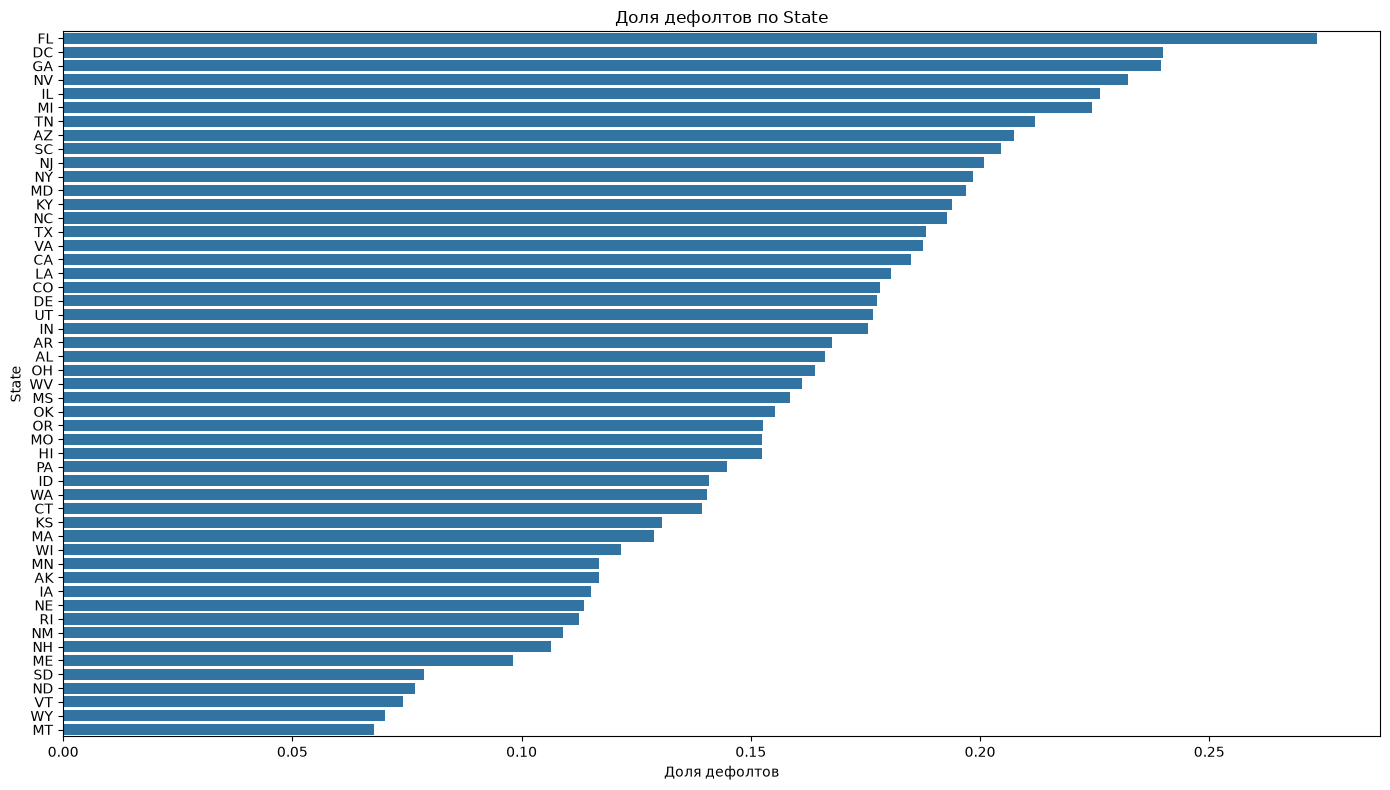

In [8]:
explore_by_nomin('State')

Топ 10 долей по NAICS
NAICS
53    0.286385
52    0.283488
48    0.267405
51    0.247913
61    0.241556
56    0.234389
45    0.233570
23    0.232017
49    0.228726
44    0.223492
Name: MIS_Status, dtype: float64


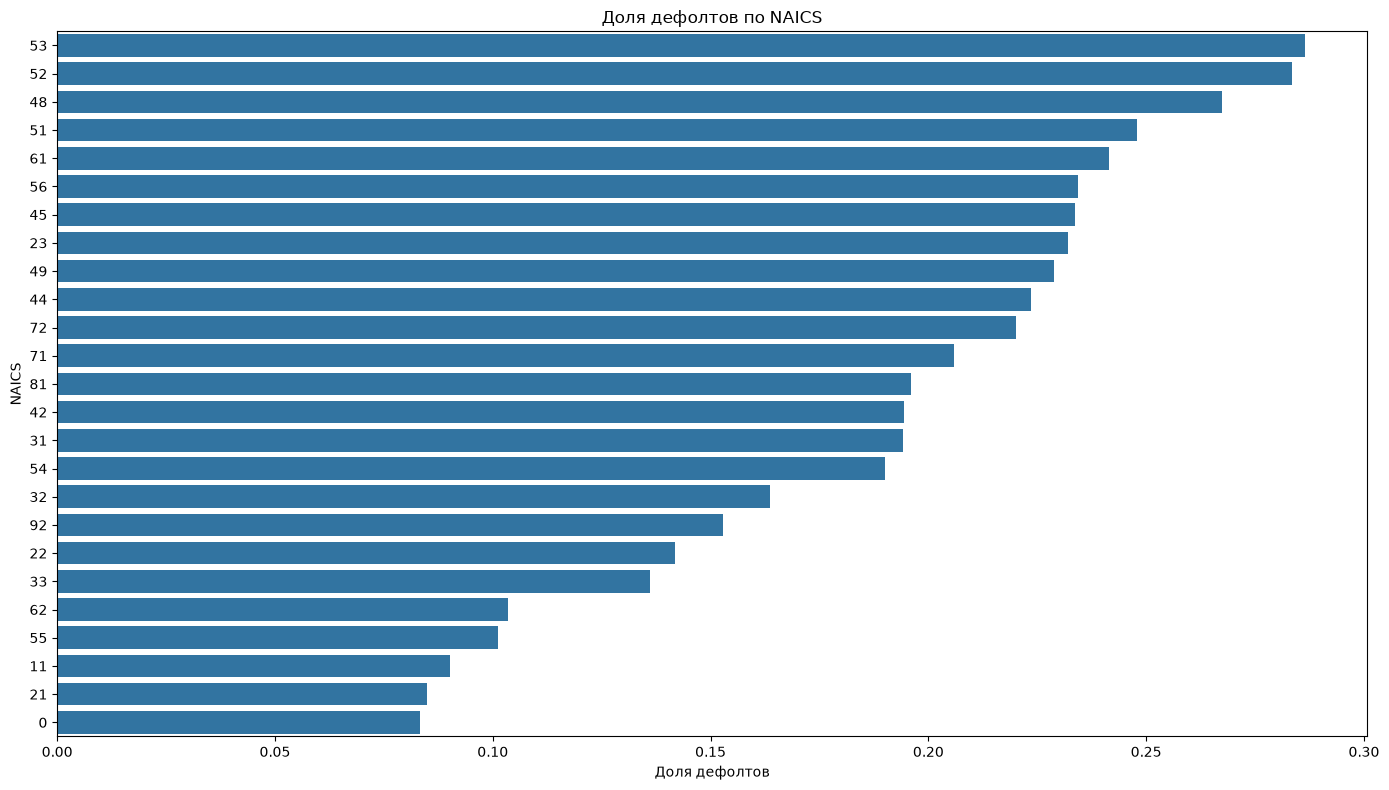

In [9]:
explore_by_nomin('NAICS')

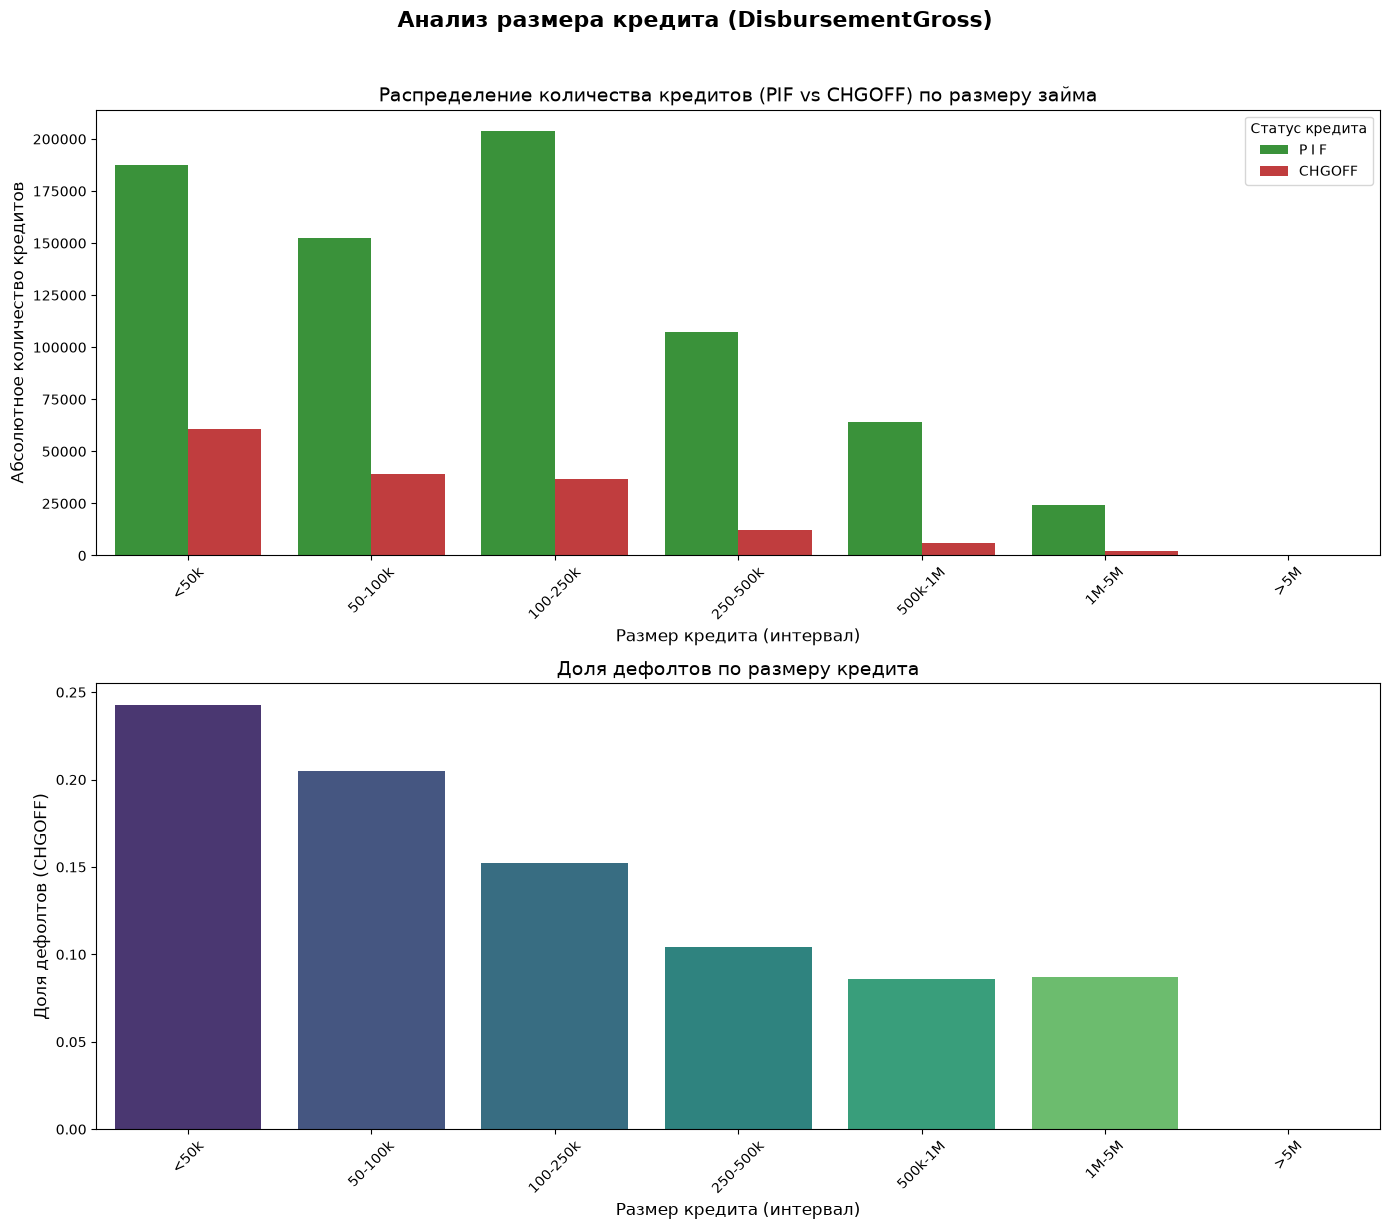

In [383]:
# 1. Очистка и конвертация колонки в числовой формат
df['DisbursementGross'] = (
    df['DisbursementGross']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

# 2. Создаем бины для размера кредита
bins = [0, 50000, 100000, 250000, 500000, 1000000, 5000000, np.inf]
labels = ['<50k', '50-100k', '100-250k', '250-500k', '500k-1M', '1M-5M', '>5M']

df['Loan_Bin'] = pd.cut(df['DisbursementGross'], bins=bins, labels=labels, right=False)

# 3. Создаем единое полотно 2x1
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Верхний график: абсолютные количества ---
sns.countplot(
    data=df,
    x='Loan_Bin',
    hue='MIS_Status',
    order=labels,
    palette=['#2ca02c', '#d62728'],
    ax=axes[0]
)
axes[0].set_title('Распределение количества кредитов (PIF vs CHGOFF) по размеру займа', fontsize=14)
axes[0].set_xlabel('Размер кредита (интервал)', fontsize=12)
axes[0].set_ylabel('Абсолютное количество кредитов', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Статус кредита')

# --- Нижний график: доля дефолтов ---
default_by_loan = df.groupby('Loan_Bin')['MIS_Status'].apply(
    lambda x: (x == 'CHGOFF').mean()
)

sns.barplot(
    x=default_by_loan.index,
    y=default_by_loan.values,
    palette='viridis',
    order=labels,  # фиксируем порядок, как в верхнем графике
    ax=axes[1]
)
axes[1].set_title('Доля дефолтов по размеру кредита', fontsize=14)
axes[1].set_xlabel('Размер кредита (интервал)', fontsize=12)
axes[1].set_ylabel('Доля дефолтов (CHGOFF)', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

# 4. Общий заголовок и отображение
fig.suptitle('Анализ размера кредита (DisbursementGross)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

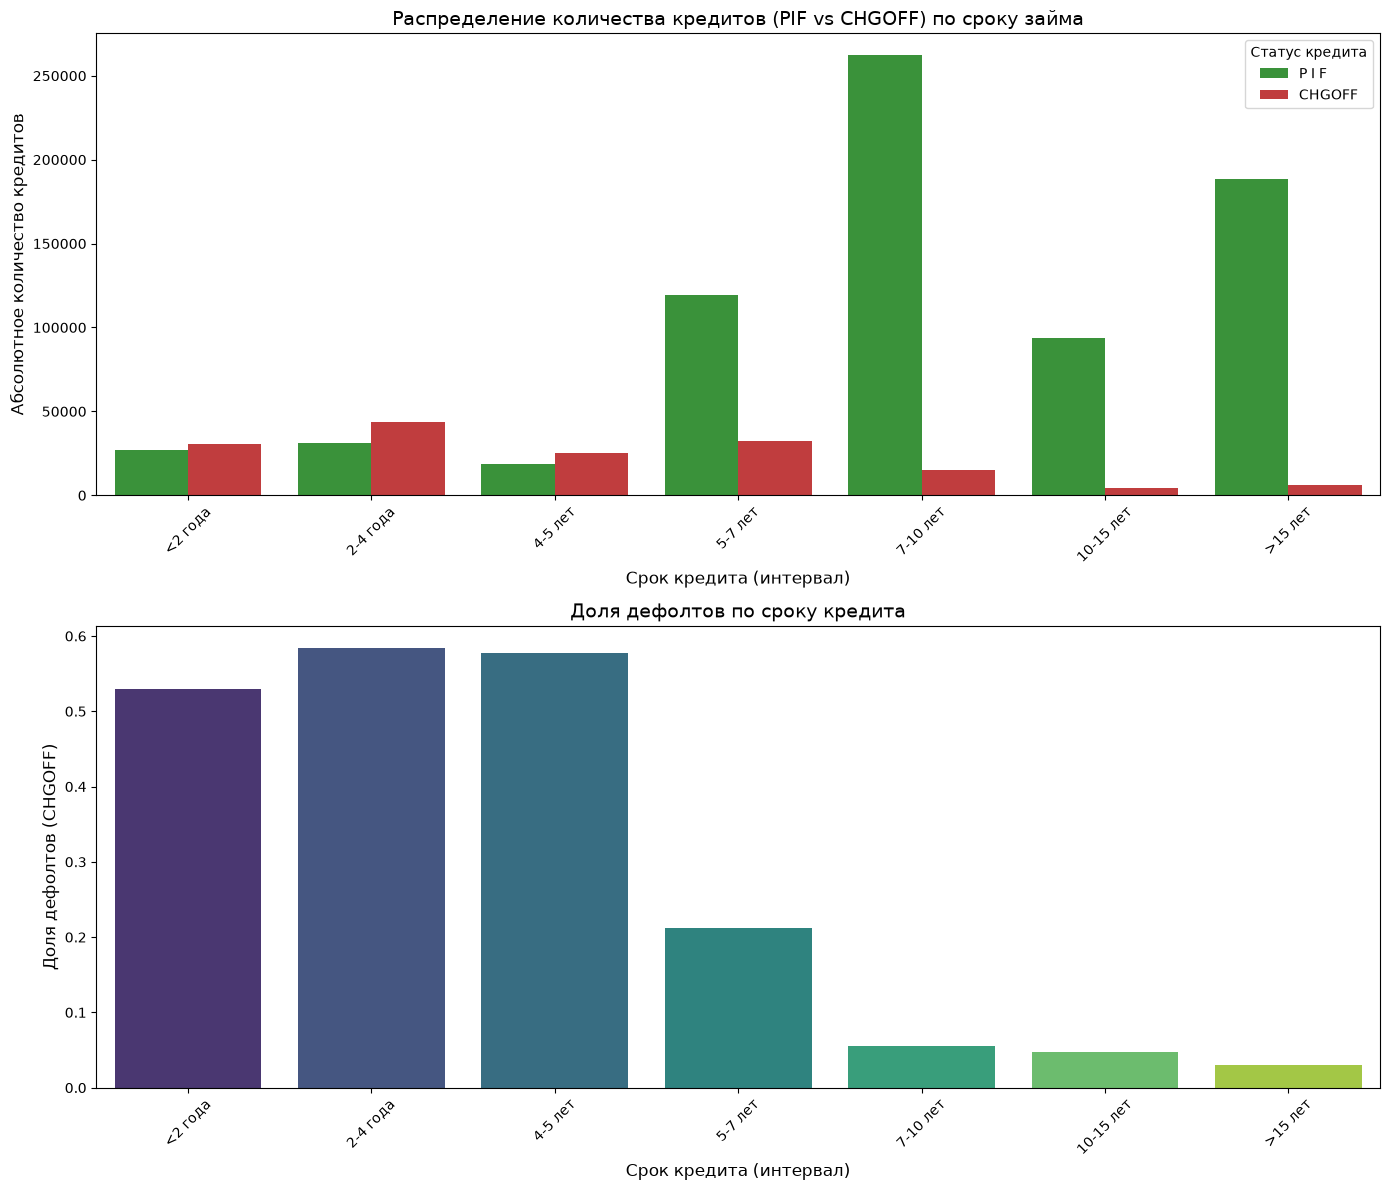

In [384]:
# 1. Создаем бины для срока кредита (в месяцах)
bins_term = [0, 24, 48, 60, 84, 120, 180, np.inf]
labels_term = ['<2 года', '2-4 года', '4-5 лет', '5-7 лет', '7-10 лет', '10-15 лет', '>15 лет']

# 2. Добавляем колонку с бинами
df['Term_Bin'] = pd.cut(df['Term'], bins=bins_term, labels=labels_term, right=False)

# 3. Создаем единое полотно 2x1
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Верхний график: абсолютные количества ---
sns.countplot(
    data=df,
    x='Term_Bin',
    hue='MIS_Status',
    order=labels_term,
    palette=['#2ca02c', '#d62728'],
    ax=axes[0]  # <-- рисуем на первой оси
)
axes[0].set_title('Распределение количества кредитов (PIF vs CHGOFF) по сроку займа', fontsize=14)
axes[0].set_xlabel('Срок кредита (интервал)', fontsize=12)
axes[0].set_ylabel('Абсолютное количество кредитов', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Статус кредита')

# --- Нижний график: доля дефолтов ---
default_by_term = df.groupby('Term_Bin')['MIS_Status'].apply(
    lambda x: (x == 'CHGOFF').mean()
)

sns.barplot(
    x=default_by_term.index,
    y=default_by_term.values,
    palette='viridis',
    ax=axes[1]  # <-- рисуем на второй оси
)
axes[1].set_title('Доля дефолтов по сроку кредита', fontsize=14)
axes[1].set_xlabel('Срок кредита (интервал)', fontsize=12)
axes[1].set_ylabel('Доля дефолтов (CHGOFF)', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

# 4. Один общий вызов show() и подгонка отступов
plt.tight_layout()
plt.show()

## 2. Прогнозирование дефолта (PD-модель)

## Предобработка данных

In [385]:
df = pd.read_csv('SBAnational.csv')

In [324]:
df.drop(['LoanNr_ChkDgt', 'Name', 'City', 'Zip', 'Bank', 'ApprovalDate', 'DisbursementDate'], axis=1, inplace=True)

In [325]:
df.drop(['ChgOffPrinGr', 'ChgOffDate', 'BalanceGross'], axis=1, inplace=True)

In [326]:
df['NAICS'] = df['NAICS'].apply(lambda n: str(n)[:2])

In [327]:
df.drop(df[~df['LowDoc'].isin(['Y','N'])].index, inplace=True)

In [328]:
df['RevLineCr'] = df['RevLineCr'].map({'1': 'Y', '0': 'N', 'Y': 'Y', 'N': 'N'})

In [329]:
df['IsFranchise'] = df['FranchiseCode'].apply(lambda n: 1 if n not in [00000, 1] else 0)
df.drop('FranchiseCode', axis=1, inplace=True)

In [330]:
df = df.dropna(subset=['RevLineCr', 'MIS_Status','BankState','NewExist', 'State'])

In [331]:
df.isnull().sum()

State                0
BankState            0
NAICS                0
ApprovalFY           0
Term                 0
NoEmp                0
NewExist             0
CreateJob            0
RetainedJob          0
UrbanRural           0
RevLineCr            0
LowDoc               0
DisbursementGross    0
MIS_Status           0
GrAppv               0
SBA_Appv             0
IsFranchise          0
dtype: int64

In [332]:
for col in ['DisbursementGross', 'GrAppv', 'SBA_Appv']:
    df[col] = (
    df[col]
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [333]:
df['ApprovalFY'] = df['ApprovalFY'].astype(str).str.extract(r'(\d{4})', expand=False).astype(int)

In [334]:
df['Default'] = df['MIS_Status'].map({'P I F': 0, 'CHGOFF': 1})
df.drop('MIS_Status', axis=1, inplace=True)

In [335]:
df_lr = pd.get_dummies(df, columns=['NAICS', 'State', 'BankState', 'UrbanRural', 
                                     'NewExist', 'RevLineCr', 'LowDoc'], 
                       drop_first=True)

df_nn = pd.get_dummies(df, columns=['NAICS', 'State', 'BankState', 'UrbanRural', 
                                     'NewExist', 'RevLineCr', 'LowDoc'], 
                       drop_first=False)

In [336]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
X_lr = df_lr.drop('Default', axis=1)
y = df_lr['Default']
X_train_lr, X_test_lr, y_train, y_test = train_test_split( X_lr, y, test_size=0.20, random_state=42, stratify=y)
scaler_lr = StandardScaler()
numerical_cols = ['Term', 'NoEmp', 'CreateJob', 'RetainedJob', 
                  'DisbursementGross', 'GrAppv', 'SBA_Appv', 'ApprovalFY']
X_train_lr[numerical_cols] = scaler_lr.fit_transform(X_train_lr[numerical_cols])
X_test_lr[numerical_cols] = scaler_lr.transform(X_test_lr[numerical_cols])

smote = SMOTE(random_state=42)
X_train_lr_res, y_train_res = smote.fit_resample(X_train_lr, y_train)

In [337]:
X_nn = df_nn.drop('Default', axis=1)
X_train_nn, X_test_nn, _, _ = train_test_split(X_nn, y, test_size=0.20, random_state=42, stratify=y)

scaler_nn = StandardScaler()
X_train_nn[numerical_cols] = scaler_nn.fit_transform(X_train_nn[numerical_cols])
X_test_nn[numerical_cols] = scaler_nn.transform(X_test_nn[numerical_cols])

# SMOTE
X_train_nn_res, y_train_nn_res = smote.fit_resample(X_train_nn, y_train)

## Экономические и модельные метрики

In [338]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
metrics_for_pd_model = []

def describe_the_results(name_of_model, model_preds, y, threshold=0.5):
    """
    Вычисляет метрики модели и сохраняет их в список metrics_for_pd_model.
    """
    y_pred = np.where(model_preds > threshold, 1, 0)

    results = (
        roc_auc_score(y, model_preds),
        average_precision_score(y, model_preds),
        f1_score(y, y_pred),
        precision_score(y, y_pred),
        recall_score(y, y_pred)
    )

    names_of_metrics = ('ROC-AUC', 'PR-AUC', 'F1-score', 'Precision', 'Recall')
    metrics_for_pd_model.append({name_of_model: results})

    # Визуализация Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(y, y_pred, cmap='Blues')
    plt.title(f'Confusion Matrix — модель {name_of_model}')
    plt.show()

    return pd.DataFrame(columns=names_of_metrics, data=[results], index=[name_of_model])


In [386]:
needed_df = pd.read_csv('SBAnational.csv')

# 2. Очищаем колонку ChgOffPrinGr от символов и конвертируем в float
needed_df['ChgOffPrinGr'] = (
    needed_df['ChgOffPrinGr']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

# 3. Берём значения по индексам train и добавляем Default
train_with_chgoff = X_train.copy()
train_with_chgoff['ChgOffPrinGr'] = needed_df.loc[X_train.index, 'ChgOffPrinGr']
train_with_chgoff['Default'] = y_train

# 4. Считаем средний ChgOffPrinGr по дефолтам
avg_chgoff = train_with_chgoff.loc[train_with_chgoff['Default'] == 1, 'ChgOffPrinGr'].mean()

print(f"Средний размер дефолта (из train): ${avg_chgoff:,.2f}")

# 2. Применяем это знание к тестовой выборке для расчёта потерь
def calculate_economic_loss(y_true, y_pred, avg_chgoff, threshold=0.5, fp_cost=1000):
    y_pred = np.where(y_pred > threshold, 1, 0)

    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    
    fn_count = ((y_true == 1) & (y_pred == 0)).sum()
    fp_count = ((y_true == 0) & (y_pred == 1)).sum()
    
    fn_loss = fn_count * avg_chgoff  # ← используем avg из train
    fp_loss = fp_count * fp_cost
    total_loss = fn_loss + fp_loss
    
    return {
        'fn_count': fn_count,
        'fp_count': fp_count,
        'fn_loss': fn_loss,
        'fp_loss': fp_loss,
        'total_loss': total_loss
    }

Средний размер дефолта (из train): $78,043.40


## Построение модели логистической регрессии

In [340]:
from sklearn.linear_model import LogisticRegression

In [342]:
log_regression = LogisticRegression(max_iter=1000)
log_regression.fit(X_train_lr_res, y_train_res)
log_preds = log_regression.predict_proba(X_test_lr)[:, 1]

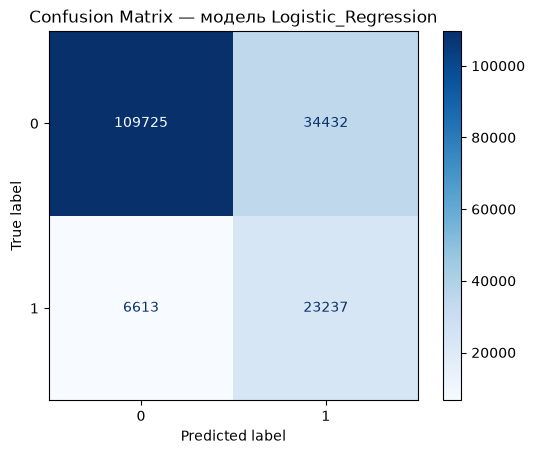

,ROC-AUC,PR-AUC,F1-score,Precision,Recall
Logistic_Regression,0.837173,0.545625,0.531016,0.402937,0.778459


In [343]:
describe_the_results('Logistic_Regression', log_preds, y_test)

## Построение MLP модели

In [344]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [345]:
def build_mlp(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
        layers.Dropout(0.2),
        layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')])

    model.compile(
        optimizer='adam',
        loss = 'binary_crossentropy',
        metrics=['accuracy']
    )

    return model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    min_delta=0.0001
)

In [347]:
model_mlp = build_mlp(input_dim=X_train_nn_res.shape[1])
model_mlp.fit(X_train_nn_res, y_train_nn_res, epochs=50, batch_size=256, validation_split=0.2, callbacks=[early_stop], verbose=1)

Epoch 1/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8408 - loss: 0.5045 - val_accuracy: 0.8407 - val_loss: 0.4566
Epoch 2/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8612 - loss: 0.4171 - val_accuracy: 0.8141 - val_loss: 0.4895
Epoch 3/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8680 - loss: 0.3981 - val_accuracy: 0.7842 - val_loss: 0.5416
Epoch 4/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8738 - loss: 0.3859 - val_accuracy: 0.8108 - val_loss: 0.4860
Epoch 5/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8774 - loss: 0.3775 - val_accuracy: 0.8620 - val_loss: 0.3952
Epoch 6/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8793 - loss: 0.3717 - val_accuracy: 0.8362 - val_loss: 0.4295
Epoch 7/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8806 - loss: 0.3675 - val_accuracy: 0.8513 - val_loss: 0.4167
Epoch 8/50
3604/3604 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.8820 - loss: 0.3639 -

In [349]:
mlp_preds = model_mlp.predict(X_test_nn)

5438/5438 ━━━━━━━━━━━━━━━━━━━━ 4s 675us/step


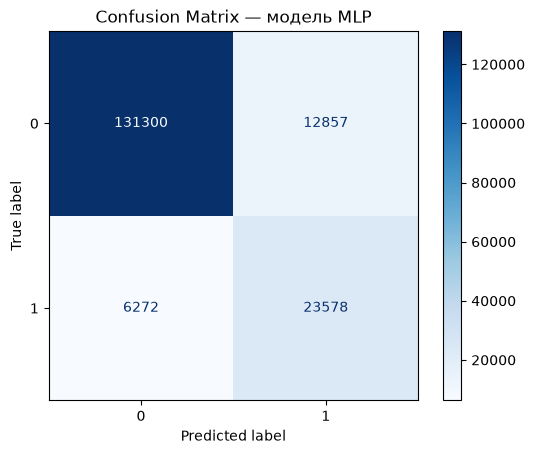

,ROC-AUC,PR-AUC,F1-score,Precision,Recall
MLP,0.926584,0.789479,0.711413,0.647125,0.789883


In [350]:
describe_the_results('MLP', mlp_preds, y_test)

## Построение 1D CNN модели

In [351]:
# 1. Определяем порядок групп признаков
feature_groups = {
    'geography': [col for col in list(X_nn.columns) if col.startswith('State') or col.startswith('BankState') or col.startswith('Urban')],
    'industry': [col for col in list(X_nn.columns) if col.startswith('NAICS')],
    'loan_params': ['Term', 'DisbursementGross', 'GrAppv', 'SBA_Appv'],
    'business_profile': ['NoEmp', 'CreateJob', 'RetainedJob', 'NewExist_1.0', 'NewExist_2.0'],
    'time_conditions': ['ApprovalFY', 'IsFranchise', 'RevLineCr_Y', 'LowDoc_Y']
}

# 2. Собираем упорядоченный список признаков
ordered_features = []
for group in ['geography', 'industry', 'loan_params', 'business_profile', 'time_conditions']:
    ordered_features.extend(feature_groups[group])

# 3. Переупорядочиваем DataFrame
X_train_ordered = X_train_nn_res[ordered_features]
X_test_ordered = X_test_nn[ordered_features]

# 4. Добавляем измерение для CNN: (batch, steps, channels)
# steps = количество признаков, channels = 1 (один "канал" на признак)
X_train_nn_ordered = X_train_nn_res[ordered_features]
X_test_nn_ordered = X_test_nn[ordered_features]

X_train_cnn = X_train_nn_ordered.values.reshape(-1, len(ordered_features), 1).astype('float32')
X_test_cnn = X_test_nn_ordered.values.reshape(-1, len(ordered_features), 1).astype('float32')

print(f"Форма входа для CNN: {X_train_cnn.shape}")

Форма входа для CNN: (1153258, 148, 1)


In [ ]:
def build_cnn1d(input_dim):
    model = models.Sequential([
        # Входной слой: (144 признака, 1 канал)
        layers.Input(shape=(input_dim, 1)),
         # === БЛОК СВЁРТКИ №1 ===
        layers.Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),
        # === БЛОК СВЁРТКИ №2 ===
        layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),
        
        layers.Flatten(),
        # === ПОЛНОСВЯЗНАЯ "ГОЛОВА" ===
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
         # === ВЫХОДНОЙ СЛОЙ ===
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [352]:
model_cnn1d = build_cnn1d(input_dim=len(ordered_features))
model_cnn1d.fit(X_train_cnn, y_train_nn_res,
    epochs=30,
    batch_size=2048,  # большой батч для CPU
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 110s 239ms/step - accuracy: 0.8381 - loss: 0.3794 - val_accuracy: 0.0809 - val_loss: 2.3575
Epoch 2/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 107s 237ms/step - accuracy: 0.8829 - loss: 0.2913 - val_accuracy: 0.7729 - val_loss: 0.4868
Epoch 3/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 107s 238ms/step - accuracy: 0.8928 - loss: 0.2706 - val_accuracy: 0.7922 - val_loss: 0.4515
Epoch 4/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 108s 238ms/step - accuracy: 0.8982 - loss: 0.2594 - val_accuracy: 0.9198 - val_loss: 0.1812
Epoch 5/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 107s 238ms/step - accuracy: 0.9013 - loss: 0.2518 - val_accuracy: 0.8382 - val_loss: 0.3660
Epoch 6/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 107s 237ms/step - accuracy: 0.9048 - loss: 0.2443 - val_accuracy: 0.8414 - val_loss: 0.3518
Epoch 7/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 107s 237ms/step - accuracy: 0.9072 - loss: 0.2390 - val_accuracy: 0.8955 - val_loss: 0.2477
Epoch 8/30
451/451 ━━━━━━━━━━━━━━━━━━━━ 107s 237ms/step - accuracy: 0.9095 -

In [353]:
cnn1d_preds = model_cnn1d.predict(X_test_cnn)

5438/5438 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step


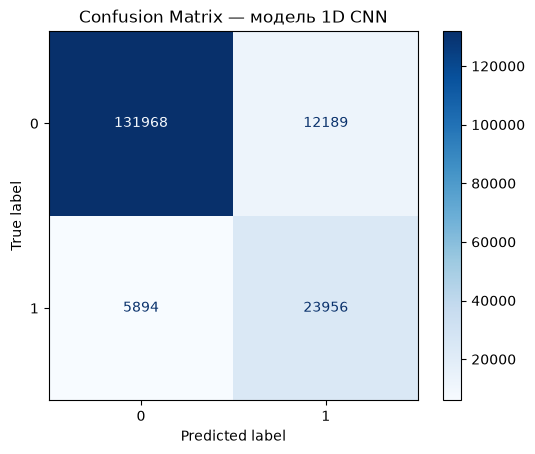

,ROC-AUC,PR-AUC,F1-score,Precision,Recall
1D CNN,0.938364,0.80863,0.725994,0.662775,0.802546


In [354]:
describe_the_results('1D CNN', cnn1d_preds, y_test)

## Сравнение моделей по метрикам

In [355]:
# 1. Преобразуем список словарей в DataFrame
# Разворачиваем
comparison_df = pd.DataFrame({
    k: v for d in metrics_for_pd_model for k, v in d.items()
}).T
comparison_df.columns = ['ROC-AUC', 'PR-AUC', 'F1-score', 'Precision', 'Recall']

# 3. Выводим таблицу
print("\n" + "="*70)
print("СРАВНЕНИЕ МОДЕЛЕЙ ПО СТАТИСТИЧЕСКИМ МЕТРИКАМ")
print("="*70)
print(comparison_df.round(4))
print("="*70)

# 4. Находим лучшую модель по каждой метрике
print("\n🏆 ЛУЧШИЕ МОДЕЛИ ПО КАЖДОЙ МЕТРИКЕ:\n")
for metric in comparison_df.columns:
    best_model = comparison_df[metric].idxmax()
    best_value = comparison_df.loc[best_model, metric]
    print(f"  {metric:<12}: {best_model} ({best_value:.4f})")


СРАВНЕНИЕ МОДЕЛЕЙ ПО СТАТИСТИЧЕСКИМ МЕТРИКАМ
                     ROC-AUC  PR-AUC  F1-score  Precision  Recall
Logistic_Regression   0.8372  0.5456    0.5310     0.4029  0.7785
MLP                   0.9266  0.7895    0.7114     0.6471  0.7899
1D CNN                0.9384  0.8086    0.7260     0.6628  0.8025

🏆 ЛУЧШИЕ МОДЕЛИ ПО КАЖДОЙ МЕТРИКЕ:

  ROC-AUC     : 1D CNN (0.9384)
  PR-AUC      : 1D CNN (0.8086)
  F1-score    : 1D CNN (0.7260)
  Precision   : 1D CNN (0.6628)
  Recall      : 1D CNN (0.8025)


In [356]:
# Словарь моделей (вероятности)
models_proba = {
    'LogReg': log_preds,      # вероятности от LogisticRegression
    'MLP': mlp_preds,         # вероятности от MLP
    '1D CNN': cnn1d_preds     # вероятности от CNN
}

# Считаем потери для каждой модели
results = {}
for name, proba in models_proba.items():
    results[name] = calculate_economic_loss(y_test, proba, avg_chgoff, fp_cost=1000)

# Выводим таблицу
comparison_df = pd.DataFrame(results).T
print("\n" + "="*70)
print("СРАВНЕНИЕ МОДЕЛЕЙ ПО ЭКОНОМИЧЕСКИМ ПОТЕРЯМ")
print("="*70)
print(comparison_df)
print("="*70)

best_model = comparison_df['total_loss'].idxmin()
print(f"\n🏆 Лучшая модель: {best_model}")
print(f"   Суммарные потери: ${comparison_df.loc[best_model, 'total_loss']:,.2f}")


СРАВНЕНИЕ МОДЕЛЕЙ ПО ЭКОНОМИЧЕСКИМ ПОТЕРЯМ
        fn_count  fp_count       fn_loss     fp_loss    total_loss
LogReg    6613.0   34432.0  5.161010e+08  34432000.0  5.505330e+08
MLP       6272.0   12857.0  4.894882e+08  12857000.0  5.023452e+08
1D CNN    5894.0   12189.0  4.599878e+08  12189000.0  4.721768e+08

🏆 Лучшая модель: 1D CNN
   Суммарные потери: $472,176,785.76


## 3. Прогнозирование потерь при дефолте (LGD-модель)

## Предобработка данных

In [387]:
df = pd.read_csv('SBAnational.csv')

In [289]:
for col in ['ChgOffPrinGr','DisbursementGross', 'GrAppv', 'SBA_Appv']:
    df[col] = (
    df[col]
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [290]:
df['LGD'] = df['ChgOffPrinGr'] / df['DisbursementGross']
df['LGD'] = df['LGD'].clip(0, 1)

In [291]:
df = df[df['MIS_Status'] == 'CHGOFF']

In [292]:
df.drop(['LoanNr_ChkDgt', 'Name', 'City', 'Zip', 'Bank', 'ApprovalDate', 'DisbursementDate', 'DisbursementGross',
         'ChgOffPrinGr', 'ChgOffDate', 'BalanceGross', 'MIS_Status'], axis=1, inplace=True)

In [293]:
df['Portion'] = df['SBA_Appv'] / df['GrAppv']
df['Portion'] = df['Portion'].fillna(0)
df['Portion'] = df['Portion'].clip(0, 1)
df['RealEstate'] = (df['Term'] >= 240).astype(int)

In [294]:
df['NAICS'] = df['NAICS'].apply(lambda n: str(n)[:2])

In [295]:
df.drop(df[~df['LowDoc'].isin(['Y','N'])].index, inplace=True)

In [296]:
df['RevLineCr'] = df['RevLineCr'].map({'1': 'Y', '0': 'N', 'Y': 'Y', 'N': 'N'})

In [297]:
df['IsFranchise'] = df['FranchiseCode'].apply(lambda n: 1 if n not in [00000, 1] else 0)
df.drop('FranchiseCode', axis=1, inplace=True)

In [298]:
df = df.dropna(subset=['RevLineCr','BankState','NewExist', 'State'])

In [299]:
df.isnull().sum()

State          0
BankState      0
NAICS          0
ApprovalFY     0
Term           0
NoEmp          0
NewExist       0
CreateJob      0
RetainedJob    0
UrbanRural     0
RevLineCr      0
LowDoc         0
GrAppv         0
SBA_Appv       0
LGD            0
Portion        0
RealEstate     0
IsFranchise    0
dtype: int64

In [300]:
df['ApprovalFY'] = df['ApprovalFY'].astype(str).str.extract(r'(\d{4})', expand=False).astype(int)

In [301]:
categorical_cols = ['NAICS', 'State', 'BankState', 'UrbanRural', 'NewExist', 'RevLineCr', 'LowDoc']
X_nn = pd.get_dummies(df, columns=categorical_cols, drop_first=False)
X_lr = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [302]:
X_nn = X_nn.drop('LGD', axis=1)
X_lr = X_lr.drop('LGD', axis=1)
y = df['LGD']
X_train_nn, X_test_nn, y_train, y_test = train_test_split(X_nn, y, test_size=0.20, random_state=42)
X_train_lr, X_test_lr, _, _ = train_test_split(X_lr, y, test_size=0.20, random_state=42)

In [303]:
scaler = StandardScaler()
numerical_cols = ['Term', 'NoEmp', 'CreateJob', 'RetainedJob', 'GrAppv', 'SBA_Appv', 'ApprovalFY']
X_train_nn[numerical_cols] = scaler.fit_transform(X_train_nn[numerical_cols])
X_test_nn[numerical_cols] = scaler.transform(X_test_nn[numerical_cols])

X_train_lr[numerical_cols] = scaler.fit_transform(X_train_lr[numerical_cols])
X_test_lr[numerical_cols] = scaler.transform(X_test_lr[numerical_cols])

## Экономические и модельные метрики

In [304]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)
import scipy.stats as stats

metrics_for_lgd_model = []

def describe_the_results_lgd(name_of_model, y_true, y_pred):
    """
    Вычисляет метрики LGD-модели и сохраняет их в список metrics_for_lgd_model.
    Также строит обязательный анализ остатков.
    
    Parameters:
    - name_of_model: название модели (строка)
    - y_true: истинные значения LGD
    - y_pred: предсказанные значения LGD
    """
    # Конвертируем в numpy для безопасности
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    
    # Ограничиваем предсказания [0, 1] (по требованию Basel III)
    y_pred = np.clip(y_pred, 0, 1)
    
    # 1. Считаем метрики
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    wmape = np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100
    
    results = (rmse, mae, r2, wmape)
    names_of_metrics = ('RMSE', 'MAE', 'R²', 'WMAPE (%)')
    
    metrics_for_lgd_model.append({name_of_model: results})
    
    # 2. Вывод результатов
    print(f"=== Метрики модели {name_of_model} ===")
    for metric_name, value in zip(names_of_metrics, results):
        if metric_name == 'MAPE (%)':
            print(f"{metric_name}: {value:.2f}%")
        else:
            print(f"{metric_name}: {value:.4f}")
    
    # 3. Анализ остатков (ОБЯЗАТЕЛЬНО по кейсу)
    residuals = y_true - y_pred
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Гистограмма остатков
    axes[0].hist(residuals, bins=50, edgecolor='black', alpha=0.7)
    axes[0].axvline(residuals.mean(), color='red', linestyle='--', label=f'Среднее = {residuals.mean():.4f}')
    axes[0].set_title(f'Гистограмма остатков ({name_of_model})')
    axes[0].set_xlabel('Остаток (y_true - y_pred)')
    axes[0].set_ylabel('Частота')
    axes[0].legend()
    
    # QQ-plot (проверка нормальности)
    stats.probplot(residuals, dist="norm", plot=axes[1])
    axes[1].set_title(f'QQ-plot остатков ({name_of_model})')
    
    # Остатки vs предсказания (проверка гетероскедастичности)
    axes[2].scatter(y_pred, residuals, alpha=0.3, s=10)
    axes[2].axhline(y=0, color='red', linestyle='--')
    axes[2].axhline(y=residuals.std(), color='orange', linestyle=':', label=f'±1σ = {residuals.std():.4f}')
    axes[2].axhline(y=-residuals.std(), color='orange', linestyle=':')
    axes[2].set_title(f'Остатки vs Предсказания ({name_of_model})')
    axes[2].set_xlabel('Предсказанный LGD')
    axes[2].set_ylabel('Остаток')
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # 4. Дополнительная диагностика: где модель ошибается систематически
    print(f"\n--- Дополнительная диагностика ({name_of_model}) ---")
    print(f"Средний остаток: {residuals.mean():.4f} (должен быть близок к 0)")
    print(f"Стд остатков: {residuals.std():.4f}")
    print(f"Доля положительных остатков (недооценка): {(residuals > 0).mean()*100:.1f}%")
    print(f"Доля отрицательных остатков (переоценка): {(residuals < 0).mean()*100:.1f}%")
    
    return pd.DataFrame(columns=names_of_metrics, data=[results], index=[name_of_model])

## Построение модели линейной регрессии

In [305]:
from sklearn.linear_model import LinearRegression

In [306]:
lin_regression = LinearRegression()
lin_regression.fit(X_train_lr, y_train)
lin_preds = lin_regression.predict(X_test_lr)

=== Метрики модели Linear Regression ===
RMSE: 0.2397
MAE: 0.1933
R²: 0.1824
WMAPE (%): 31.3168


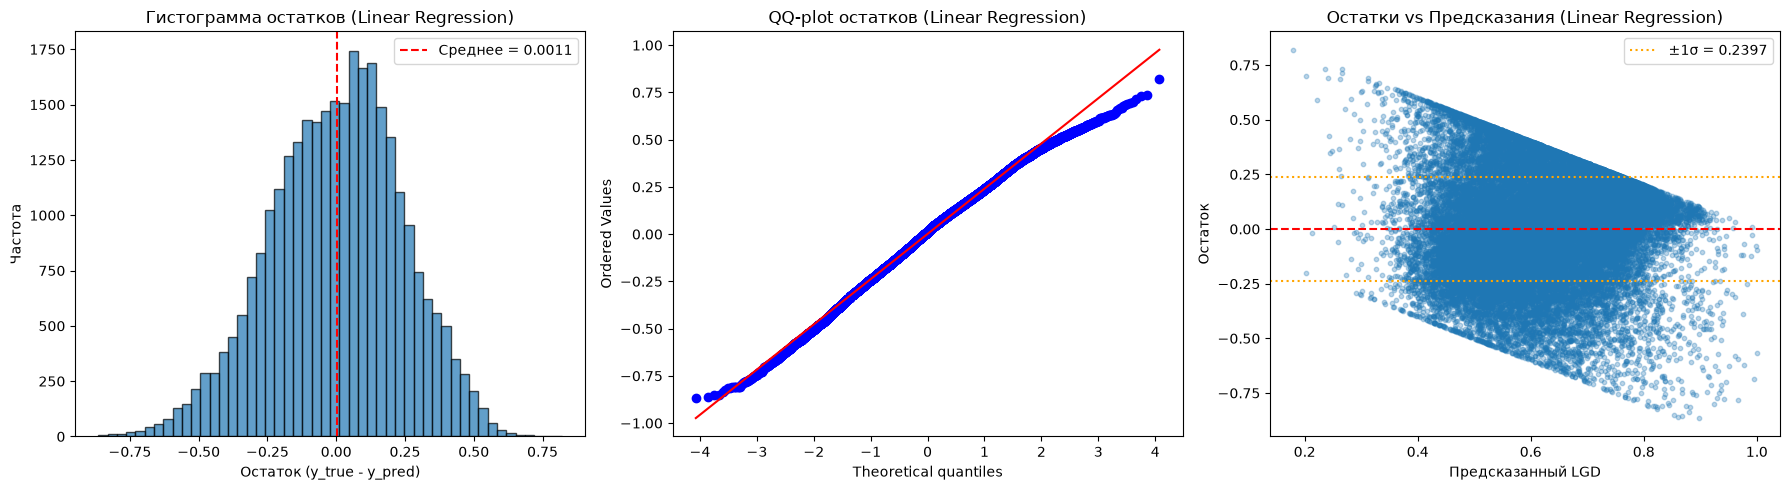


--- Дополнительная диагностика (Linear Regression) ---
Средний остаток: 0.0011 (должен быть близок к 0)
Стд остатков: 0.2397
Доля положительных остатков (недооценка): 52.0%
Доля отрицательных остатков (переоценка): 48.0%


,RMSE,MAE,R²,WMAPE (%)
Linear Regression,0.239659,0.193295,0.182403,31.316765


In [307]:
describe_the_results_lgd('Linear Regression', y_test, lin_preds)

## Построение модели MLP

In [308]:
def build_mlp_lgd(input_dim):
    model = models.Sequential([
        # Входной слой
        layers.Input(shape=(input_dim,)),
        
        # Скрытые слои: 64 → 32 → 16
        layers.Dense(64, activation='relu', 
                     kernel_regularizer=tf.keras.regularizers.l2(0.01)),
        layers.Dropout(0.2),
        
        layers.Dense(32, activation='relu',
                     kernel_regularizer=tf.keras.regularizers.l2(0.01)),
        layers.Dropout(0.2),
        
        layers.Dense(16, activation='relu',
                     kernel_regularizer=tf.keras.regularizers.l2(0.01)),
        layers.Dropout(0.2),
        
        # Выходной слой: sigmoid для строгого [0, 1]
        layers.Dense(1)  # ← без L2!
    ])
    
    model.compile(
        optimizer='adam',
        loss=tf.keras.losses.Huber(delta=0.5), 
        metrics=['mae', 'mse']                   
    )
    
    return model

# Early Stopping с восстановлением лучших весов
early_stop = EarlyStopping(
    monitor='val_loss',
    min_delta=0.001,
    patience=30,
    restore_best_weights=True,
    verbose=1
)

In [309]:
model_mlp_lgd = build_mlp_lgd(input_dim=X_train_nn.shape[1])

history = model_mlp_lgd.fit(
    X_train_nn, y_train,
    epochs=100,
    batch_size=256,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3348 - mae: 0.2335 - mse: 0.0834 - val_loss: 0.0445 - val_mae: 0.2066 - val_mse: 0.0601
Epoch 2/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0397 - mae: 0.2143 - mse: 0.0663 - val_loss: 0.0347 - val_mae: 0.2065 - val_mse: 0.0603
Epoch 3/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0363 - mae: 0.2088 - mse: 0.0632 - val_loss: 0.0345 - val_mae: 0.2045 - val_mse: 0.0592
Epoch 4/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0353 - mae: 0.2043 - mse: 0.0609 - val_loss: 0.0335 - val_mae: 0.1992 - val_mse: 0.0572
Epoch 5/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0344 - mae: 0.2006 - mse: 0.0588 - val_loss: 0.0330 - val_mae: 0.1969 - val_mse: 0.0560
Epoch 6/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0337 - mae: 0.1970 - mse: 0.0571 - val_loss: 0.0326 - val_mae: 0.1955 - val_mse: 0.0554
Epoch 7/100
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0332 - mae: 0.1951 - mse: 0.056

In [310]:
lgd_mlp_preds_raw = model_mlp_lgd.predict(X_test_nn).flatten()
lgd_mlp_preds = np.clip(lgd_mlp_preds_raw, 0, 1)

933/933 ━━━━━━━━━━━━━━━━━━━━ 1s 672us/step


=== Метрики модели MLP ===
RMSE: 0.2210
MAE: 0.1760
R²: 0.3050
WMAPE (%): 28.5154


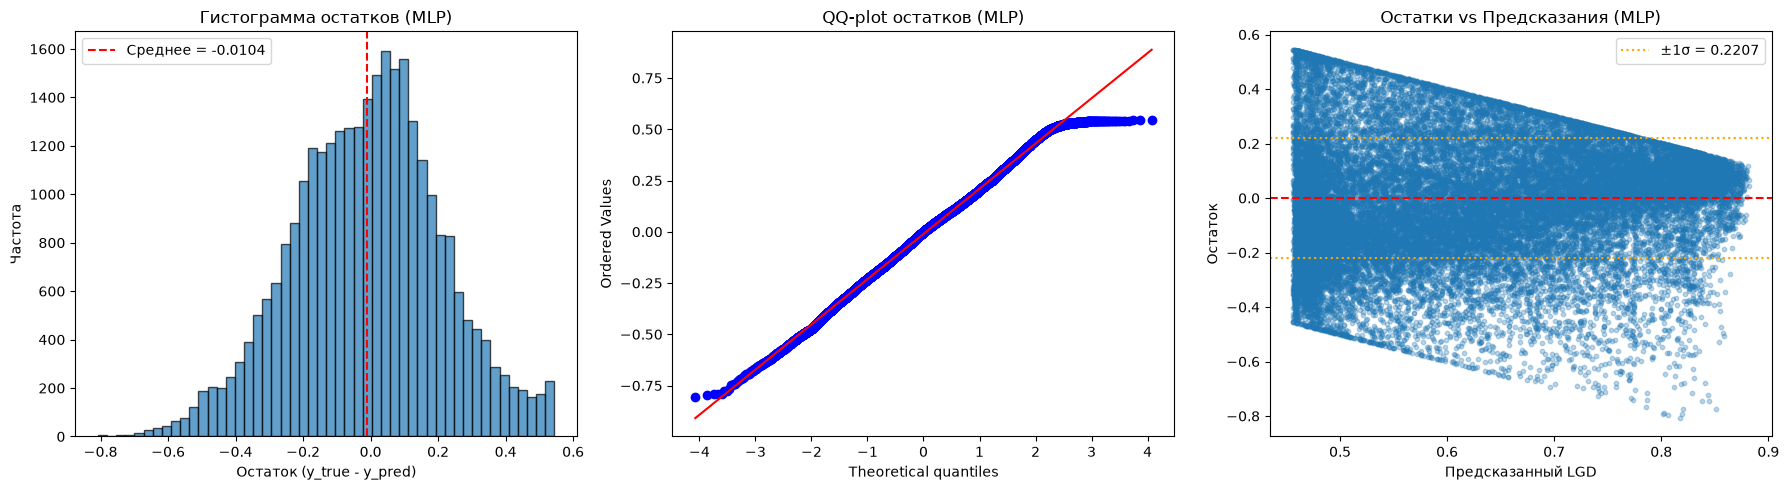


--- Дополнительная диагностика (MLP) ---
Средний остаток: -0.0104 (должен быть близок к 0)
Стд остатков: 0.2207
Доля положительных остатков (недооценка): 49.9%
Доля отрицательных остатков (переоценка): 50.1%


,RMSE,MAE,R²,WMAPE (%)
MLP,0.220964,0.176004,0.304983,28.515371


In [311]:
describe_the_results_lgd('MLP', y_test, lgd_mlp_preds)

## Построение модели 1D CNN

In [315]:
# 1. Определяем порядок групп признаков
feature_groups = {
    'geography': [col for col in X_nn.columns if col.startswith('State') or col.startswith('BankState') or col.startswith('UrbanRural')],
    'industry': [col for col in X_nn.columns if col.startswith('NAICS')],
    'loan_params': ['Term', 'GrAppv', 'SBA_Appv', 'Portion'],
    'business_profile': ['NoEmp', 'CreateJob', 'RetainedJob', 'NewExist_0.0', 'NewExist_1.0', 'NewExist_2.0', 'RealEstate'],  # ← добавили RealEstate
    'time_conditions': ['ApprovalFY', 'IsFranchise', 'RevLineCr_N', 'RevLineCr_Y', 'LowDoc_N', 'LowDoc_Y']
}

# 2. Собираем упорядоченный список признаков
ordered_features = []
for group in ['geography', 'industry', 'loan_params', 'business_profile', 'time_conditions']:
    ordered_features.extend(feature_groups[group])

# 3. Переупорядочиваем DataFrame
X_train_ordered = X_train_nn[ordered_features]
X_test_ordered = X_test_nn[ordered_features]

# 4. Добавляем измерение для CNN: (batch, steps, channels)
X_train_cnn = X_train_ordered.values.reshape(-1, len(ordered_features), 1)
X_test_cnn = X_test_ordered.values.reshape(-1, len(ordered_features), 1)

X_train_cnn = X_train_cnn.astype('float32')
X_test_cnn = X_test_cnn.astype('float32')

print(f"Форма входа для CNN: {X_train_cnn.shape}")

Форма входа для CNN: (119399, 148, 1)


In [316]:
def build_cnn_1d_lgd(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim, 1)),

        layers.Conv1D(32, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),

        layers.Conv1D(64, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),

        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),

        layers.Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss=tf.keras.losses.Huber(delta=0.5),
        metrics=['mae', 'mse']
    )
    
    return model

early_stop_lgd = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [318]:
model_cnn_lgd = build_cnn_1d_lgd(input_dim=len(ordered_features))
model_cnn_lgd.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=1024,
    validation_split=0.2,
    callbacks=[early_stop_lgd],
    verbose=1
)

Epoch 1/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 124ms/step - loss: 0.0503 - mae: 0.2562 - mse: 0.1136 - val_loss: 0.3136 - val_mae: 0.8757 - val_mse: 0.8361
Epoch 2/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 119ms/step - loss: 0.0340 - mae: 0.2098 - mse: 0.0703 - val_loss: 0.3983 - val_mae: 1.0465 - val_mse: 1.1628
Epoch 3/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 120ms/step - loss: 0.0310 - mae: 0.2002 - mse: 0.0629 - val_loss: 0.4429 - val_mae: 1.1356 - val_mse: 1.3578
Epoch 4/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 117ms/step - loss: 0.0297 - mae: 0.1957 - mse: 0.0601 - val_loss: 0.3667 - val_mae: 0.9821 - val_mse: 1.0341
Epoch 5/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 110ms/step - loss: 0.0289 - mae: 0.1927 - mse: 0.0584 - val_loss: 0.2017 - val_mae: 0.6405 - val_mse: 0.4721
Epoch 6/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 118ms/step - loss: 0.0279 - mae: 0.1889 - mse: 0.0563 - val_loss: 0.0801 - val_mae: 0.3519 - val_mse: 0.1655
Epoch 7/100
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 112ms/step - loss: 0.0275 - mae: 0.1872 - mse

In [319]:
lgd_cnn_preds_raw = model_cnn_lgd.predict(X_test_cnn).flatten()
lgd_cnn_preds = np.clip(lgd_cnn_preds_raw, 0, 1)

933/933 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


=== Метрики модели 1D CNN ===
RMSE: 0.2107
MAE: 0.1614
R²: 0.3678
WMAPE (%): 26.1497


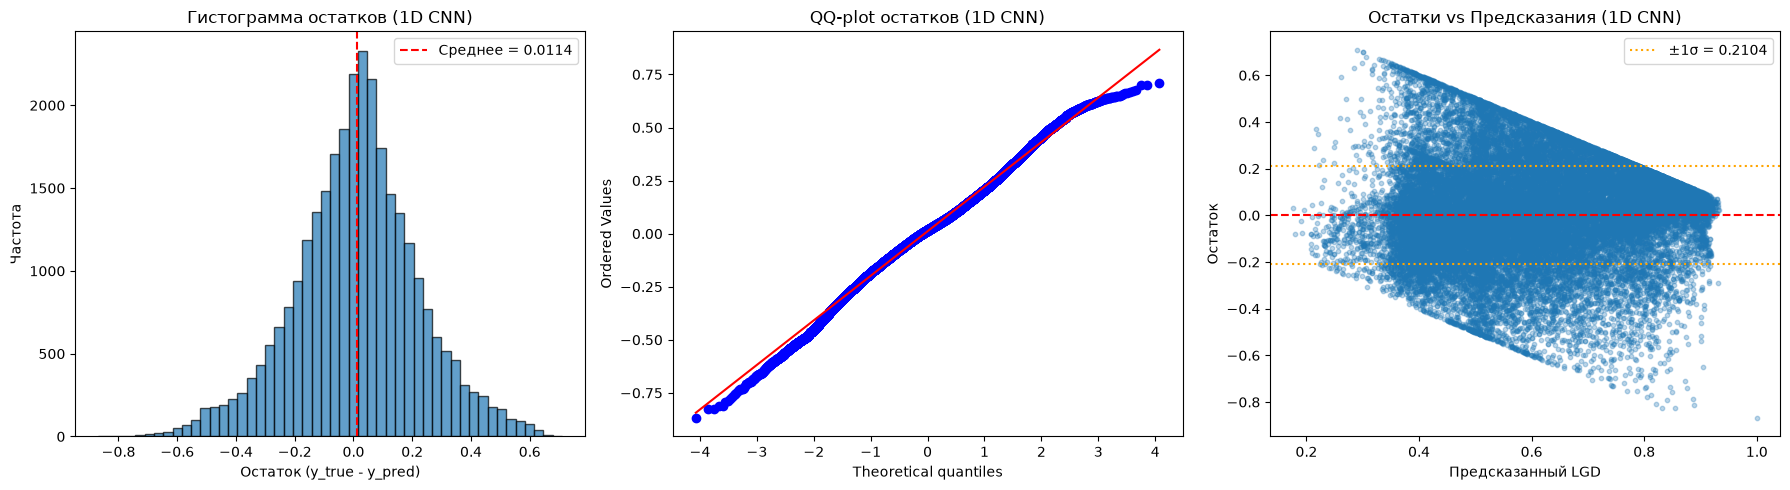


--- Дополнительная диагностика (1D CNN) ---
Средний остаток: 0.0114 (должен быть близок к 0)
Стд остатков: 0.2104
Доля положительных остатков (недооценка): 54.0%
Доля отрицательных остатков (переоценка): 46.0%


,RMSE,MAE,R²,WMAPE (%)
1D CNN,0.210742,0.161402,0.3678,26.149721


In [321]:
describe_the_results_lgd('1D CNN', y_test, lgd_cnn_preds)

## Сравнение моделей по метрикам

In [358]:
# Сравнение LGD-моделей по метрикам

# 1. Преобразуем список словарей в DataFrame
# Разворачиваем
comparison_lgd_df = pd.DataFrame({
    k: v for d in metrics_for_lgd_model for k, v in d.items()
}).T
comparison_lgd_df.columns = ['RMSE', 'MAE', 'R²', 'WMAPE (%)']

# 2. Выводим таблицу
print("\n" + "="*70)
print("СРАВНЕНИЕ МОДЕЛЕЙ ПО СТАТИСТИЧЕСКИМ МЕТРИКАМ (LGD)")
print("="*70)
print(comparison_lgd_df.round(4))
print("="*70)

# 3. Находим лучшую модель по каждой метрике
print("\n🏆 ЛУЧШИЕ МОДЕЛИ ПО КАЖДОЙ МЕТРИКЕ:\n")
for metric in comparison_lgd_df.columns:
    # Для RMSE, MAE, WMAPE - чем меньше, тем лучше
    if metric in ['RMSE', 'MAE', 'WMAPE (%)']:
        best_model = comparison_lgd_df[metric].idxmin()
    # Для R² - чем больше, тем лучше
    else:
        best_model = comparison_lgd_df[metric].idxmax()
    
    best_value = comparison_lgd_df.loc[best_model, metric]
    print(f"  {metric:<12}: {best_model} ({best_value:.4f})")

# 4. Дополнительная информация
print("\n" + "="*70)
print("ИНТЕРПРЕТАЦИЯ МЕТРИК:")
print("="*70)
print("RMSE      - штраф за крупные ошибки (чувствителен к выбросам)")
print("MAE       - средняя абсолютная ошибка (устойчивее к выбросам)")
print("R²        - доля объясненной дисперсии (чем больше, тем лучше)")
print("WMAPE     - взвешенная относительная ошибка (в %)")
print("="*70)


СРАВНЕНИЕ МОДЕЛЕЙ ПО СТАТИСТИЧЕСКИМ МЕТРИКАМ (LGD)
                     RMSE     MAE      R²  WMAPE (%)
Linear Regression  0.2397  0.1933  0.1824    31.3168
MLP                0.2210  0.1760  0.3050    28.5154
1D CNN             0.2107  0.1614  0.3678    26.1497

🏆 ЛУЧШИЕ МОДЕЛИ ПО КАЖДОЙ МЕТРИКЕ:

  RMSE        : 1D CNN (0.2107)
  MAE         : 1D CNN (0.1614)
  R²          : 1D CNN (0.3678)
  WMAPE (%)   : 1D CNN (26.1497)

ИНТЕРПРЕТАЦИЯ МЕТРИК:
RMSE      - штраф за крупные ошибки (чувствителен к выбросам)
MAE       - средняя абсолютная ошибка (устойчивее к выбросам)
R²        - доля объясненной дисперсии (чем больше, тем лучше)
WMAPE     - взвешенная относительная ошибка (в %)


## 4. Расчет Expected Loss

In [388]:
df_original = pd.read_csv('SBAnational.csv')

# Извлекаем EAD
EAD_all_raw = df_original.loc[y_test.index, 'DisbursementGross'].values

# Очищаем и конвертируем в float
EAD_all = pd.Series(EAD_all_raw).astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float).values

print(f"Тип EAD_all: {EAD_all.dtype}")
print(f"Средний EAD: ${EAD_all.mean():,.2f}")

Тип EAD_all: float64
Средний EAD: $202,982.07


In [378]:

pd_models = {
    'LogReg': log_preds,
    'MLP': mlp_preds,
    '1D CNN': cnn1d_preds
}

lgd_models = {
    'Linear Regression': lin_preds,
    'MLP': lgd_mlp_preds,
    '1D CNN': lgd_cnn_preds
}

# Конвертируем y_test в numpy
y_test_np = np.asarray(y_test).flatten().astype(float)

# === ШАГ 2: Функция расчёта EL ===
def calculate_EL(pd_proba, lgd_pred, y_test_np, EAD_all):
    """
    Рассчитывает суммарный EL для одной комбинации PD + LGD.
    LGD применяется только к дефолтным кредитам (y_test == 1).
    """
    pd_proba = np.asarray(pd_proba).flatten().astype(float)
    lgd_pred = np.asarray(lgd_pred).flatten().astype(float)
    
    # LGD только для дефолтных кредитов
    lgd_full = np.zeros(len(y_test_np))
    default_mask = (y_test_np == 1)
    lgd_full[default_mask] = np.clip(lgd_pred, 0, 1)
    
    # EL = PD × LGD × EAD
    EL = pd_proba * lgd_full * EAD_all
    
    return EL.sum()

# === ШАГ 3: 5 комбинаций из кейса ===
combinations = [
    ('Лог. регрессия', 'Линейная регрессия', log_preds, lin_preds),
    ('MLP', 'MLP', mlp_preds, lgd_mlp_preds),
    ('1D CNN', '1D CNN', cnn1d_preds, lgd_cnn_preds),
    ('MLP', '1D CNN', mlp_preds, lgd_cnn_preds),
    ('1D CNN', 'MLP', cnn1d_preds, lgd_mlp_preds),
]

results = []
for pd_name, lgd_name, pd_proba, lgd_pred in combinations:
    el_portfolio = calculate_EL(pd_proba, lgd_pred, y_test_np, EAD_all)
    results.append({
        'PD-модель': pd_name,
        'LGD-модель': lgd_name,
        'EL_portfolio': el_portfolio
    })

comparison_table = pd.DataFrame(results)

# === ШАГ 4: Вывод таблицы в формате кейса ===
print("\n" + "="*70)
print("Сравнение моделей")
print("Необходимо провести сравнение комбинаций моделей по суммарному EL:")
print("="*70)
print(f"{'PD-модель':<18} {'LGD-модель':<22} {'EL_portfolio':>22}")
print("-" * 70)

for _, row in comparison_table.iterrows():
    el_str = f"${row['EL_portfolio']:,.2f}"
    marker = " ← baseline" if row['PD-модель'] == 'Лог. регрессия' else ""
    print(f"{row['PD-модель']:<18} {row['LGD-модель']:<22} {el_str:>22}{marker}")

print("="*70)

# === ШАГ 5: Ответ на ключевой вопрос кейса ===
baseline_el = comparison_table.loc[0, 'EL_portfolio']

print("\n" + "="*70)
print("Ключевой вопрос: дает ли нейросетевая модель существенное")
print("преимущество в оценке ожидаемых потерь по сравнению с")
print("классическими статистическими методами?")
print("="*70)

# Находим лучшую нейросетевую комбинацию
nn_combinations = comparison_table[comparison_table['PD-модель'] != 'Лог. регрессия']
best_nn_idx = nn_combinations['EL_portfolio'].idxmin()
best_nn = nn_combinations.loc[best_nn_idx]

savings = baseline_el - best_nn['EL_portfolio']
savings_pct = (savings / baseline_el) * 100

print(f"\n📊 Baseline (Лог. регрессия + Линейная регрессия):")
print(f"   EL_portfolio = ${baseline_el:,.2f}")

print(f"\n🏆 Лучшая нейросетевая комбинация:")
print(f"   PD={best_nn['PD-модель']} + LGD={best_nn['LGD-модель']}")
print(f"   EL_portfolio = ${best_nn['EL_portfolio']:,.2f}")

print(f"\n💰 Разница в долларах:")
print(f"   Абсолютная: ${savings:,.2f}")
print(f"   Относительная: {savings_pct:.2f}%")

if savings < 0:
    print(f"\n⚠️ Вывод: Нейросетевые модели дают БОЛЬШИЙ EL, чем baseline.")
    print(f"   Это означает, что классические модели ЗАНИЖАЮТ риск на ${-savings:,.2f}.")
    print(f"   Нейросети выявляют скрытый риск, который не видят линейные модели.")
else:
    print(f"\n✅ Вывод: Нейросетевые модели дают МЕНЬШИЙ EL, чем baseline.")
    print(f"   Экономия: ${savings:,.2f} ({savings_pct:.2f}%)")

print("="*70)


Сравнение моделей
Необходимо провести сравнение комбинаций моделей по суммарному EL:
PD-модель          LGD-модель                       EL_portfolio
----------------------------------------------------------------------
Лог. регрессия     Линейная регрессия          $1,308,368,834.36 ← baseline
MLP                MLP                         $1,488,113,677.78
1D CNN             1D CNN                      $1,455,451,290.73
MLP                1D CNN                      $1,437,521,657.94
1D CNN             MLP                         $1,507,281,324.87

Ключевой вопрос: дает ли нейросетевая модель существенное
преимущество в оценке ожидаемых потерь по сравнению с
классическими статистическими методами?

📊 Baseline (Лог. регрессия + Линейная регрессия):
   EL_portfolio = $1,308,368,834.36

🏆 Лучшая нейросетевая комбинация:
   PD=MLP + LGD=1D CNN
   EL_portfolio = $1,437,521,657.94

💰 Разница в долларах:
   Абсолютная: $-129,152,823.57
   Относительная: -9.87%

⚠️ Вывод: Нейросетевые моде

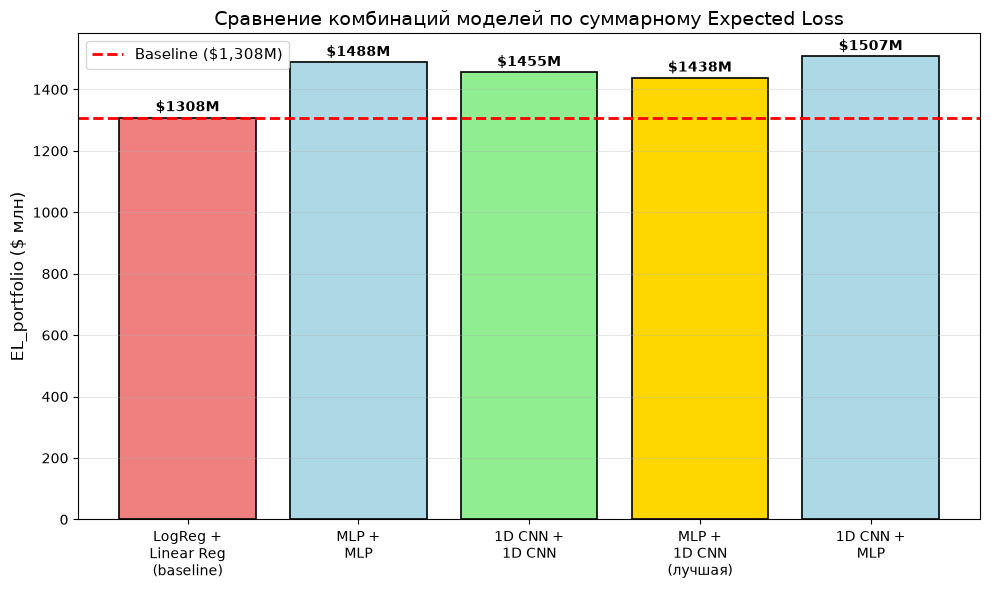

In [379]:
fig, ax = plt.subplots(figsize=(10, 6))

combinations_labels = [
    'LogReg +\nLinear Reg\n(baseline)',
    'MLP +\nMLP',
    '1D CNN +\n1D CNN',
    'MLP +\n1D CNN\n(лучшая)',
    '1D CNN +\nMLP'
]
el_values = [1308.37, 1488.11, 1455.45, 1437.52, 1507.28]
colors = ['lightcoral', 'lightblue', 'lightgreen', 'gold', 'lightblue']

bars = ax.bar(combinations_labels, el_values, color=colors, edgecolor='black', linewidth=1.2)

ax.axhline(y=1308.37, color='red', linestyle='--', linewidth=2, label='Baseline ($1,308M)')
ax.set_ylabel('EL_portfolio ($ млн)', fontsize=12)
ax.set_title('Сравнение комбинаций моделей по суммарному Expected Loss', fontsize=14)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

for bar, val in zip(bars, el_values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
            f'${val:.0f}M', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Вывод



**Результаты сравнения комбинаций моделей**

Проведённое сравнение пяти комбинаций моделей PD и LGD по суммарному Expected Loss портфеля выявило неожиданный, но методологически важный результат. Базовая комбинация классических методов (логистическая регрессия для PD + линейная регрессия для LGD) показала наименьший суммарный EL в размере 1 308 368 834 долл. Все нейросетевые комбинации дали более высокие значения — от 1 437 млн до 1 507 млн долл. Наименьший EL среди нейросетевых моделей продемонстрировала связка MLP (PD) + 1D CNN (LGD) — 1 437 521 658 долл., что на 129 152 824 долл. (9.87%) больше, чем у baseline.

**Интерпретация результата: почему больший EL — это преимущество**

На первый взгляд может показаться, что нейросетевые модели работают хуже, поскольку дают более высокую оценку потерь. Однако с точки зрения риск-менеджмента и требований Basel III, это прямо противоположно истине. Классические линейные модели систематически занижают риск за счёт неспособности улавливать нелинейные взаимодействия между признаками (например, «отрасль × регион × срок кредита»). Логистическая регрессия (ROC-AUC = 0.837) «размазывает» вероятности дефолта равномерно по портфелю, а линейная регрессия для LGD (R² = 0.16) предсказывает значения, близкие к среднему, не различая кредиты с высоким и низким уровнем потерь. В результате банк, использующий baseline-модели, недооценивает ожидаемые потери на 129 млн долл. и резервирует недостаточно капитала.

**Практическое значение для банка**

Разница в 129 млн долл. между baseline и лучшей нейросетевой комбинацией представляет собой скрытый риск, который классические статистические методы не способны выявить. В благоприятных экономических условиях занижение EL создаёт иллюзию прибыльности за счёт меньших резервов, однако при стрессовом сценарии (рост дефолтов, ухудшение макроэкономики) банк столкнётся с недостатком капитала и риском неплатежеспособности. Нейросетевые модели обеспечивают более реалистичную и регуляторно корректную оценку ожидаемых потерь, что соответствует принципам адекватного резервирования капитала.

**Оптимальная архитектура**

Интересно, что наилучший результат показала не комбинация «1D CNN + 1D CNN», а связка MLP для PD + 1D CNN для LGD. Это указывает на различную природу задач: для классификации (PD) полносвязной архитектуры MLP достаточно (ROC-AUC = 0.927, лишь немного уступает 1D CNN с 0.938), тогда как для регрессии с бимодальным распределением (LGD) свёрточные слои критически важны — они улавливают локальные взаимодействия признаков и дают прирост R² с 0.30 (MLP) до 0.37 (1D CNN). Таким образом, нейросетевые модели дают существенное преимущество в оценке ожидаемых потерь, составляющее 129 млн долл. в абсолютном выражении — именно в этой сумме заключается выявленный скрытый риск, невидимый для классических статистических методов.